In [1]:
import eu9_osm
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects

In [2]:
bbox = (-8.652592, 41.128763, -8.572683, 41.1737495)
crs = "EPSG:3763"

In [3]:
# OSM data
buildings = eu9_osm.features_from_bbox(bbox=bbox, tags={"building": True}, clip=True)
streets = eu9_osm.features_from_bbox(bbox=bbox, tags={"highway": True}, clip=True)
water = eu9_osm.features_from_bbox(bbox=bbox, tags={"natural": "water", "waterway": "riverbank"}, clip=True)
parks = eu9_osm.features_from_bbox(bbox=bbox, tags={"leisure": ["park", "garden"]}, clip=True)

In [4]:
# Reproject
buildings = buildings.to_crs(crs)
streets = streets.to_crs(crs)
water = water.to_crs(crs)
parks = parks.to_crs(crs)

In [5]:
# Keep only polygons
buildings = buildings[buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
water = water[water.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks = parks[parks.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
# Keep only lines
streets = streets[streets.geometry.geom_type.isin(["LineString", "MultiLineString"])].copy()

In [6]:
# Map extent to projected coords
extent = gpd.GeoSeries([box(*bbox)], crs="EPSG:4326").to_crs(crs)
xmin, ymin, xmax, ymax = extent.total_bounds

In [7]:
# Road lw
road_widths = {
    "motorway": 12,
    "trunk": 11,
    "primary": 10,
    "secondary": 9,
    "tertiary": 8,
    "residential": 6,
    "living_street": 5,
    "pedestrian": 5,
    "service": 3,
    "footway": 2,
    "path": 1.5,
    "steps": 2
}

In [8]:
# Buffer roads
streets["width"] = streets["highway"].map(road_widths).fillna(4)
street_polygons = streets.copy()
street_polygons["geometry"] = [geom.buffer(width / 2, cap_style=2, join_style=2) 
                               for geom, width in zip(streets.geometry, streets["width"])]

# Separate street polygons into one poly
road_union = street_polygons.geometry.union_all()
road_surface = gpd.GeoSeries([road_union], crs=crs)

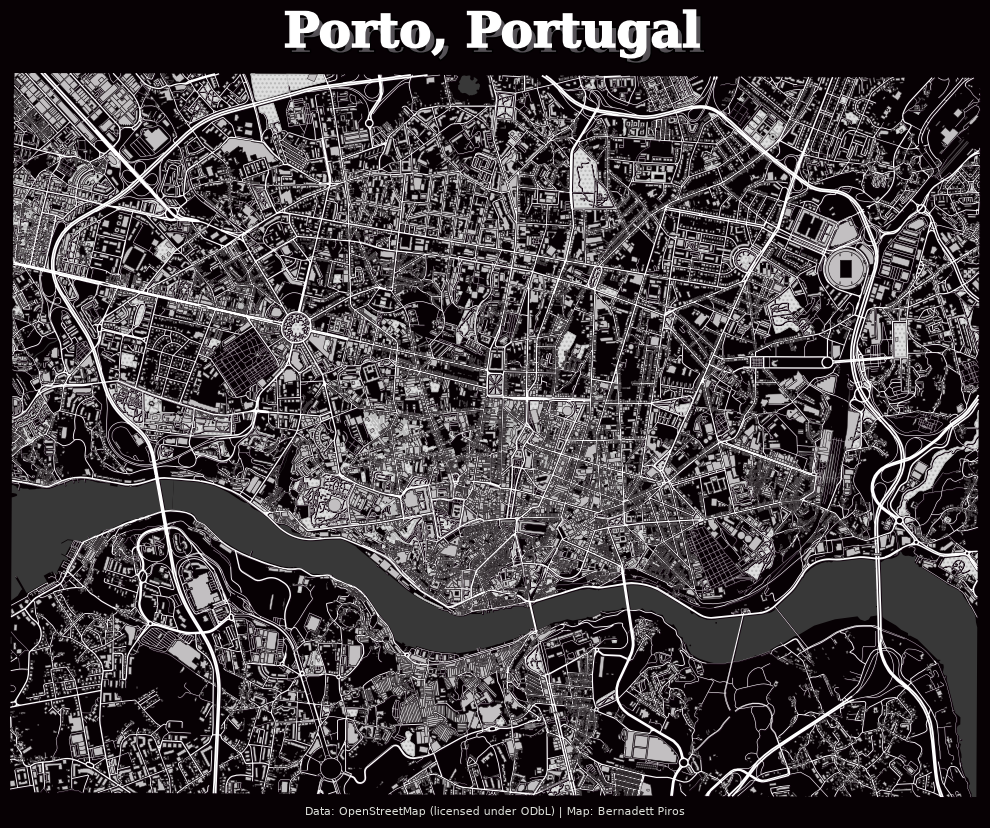

In [9]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor= "#070104")

water.plot(ax=ax, facecolor="#383838",ec="none", zorder=1)

# Parks and gardens
parks.plot(ax=ax, facecolor="#DEDEDE", hatch="....", ec="#B8B8B8", lw=0.5, zorder=2)  

# Streets outlines 
road_surface.plot(ax=ax, facecolor="#150f12", ec="#150712", lw=0.7, zorder=3)

# Streets surfaces 
road_surface.plot(ax=ax, facecolor="#FFFFFF", ec="none", zorder=4)

# Buildings
buildings.plot(ax=ax, facecolor="#c2bfc1", ec="#221c1f", lw=0.35, zorder=5)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_facecolor("#070104")
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()

# Title
txt=fig.text(0.5, 0.925,
         "Porto, Portugal",
         color="#dde0da", size=35, weight="bold", fontfamily="serif", ha="center", va="top")
txt.set_path_effects([
    path_effects.PathPatchEffect(
        offset=(4, -4), facecolor="#555156"),
    path_effects.PathPatchEffect(
        edgecolor="white", linewidth=1.1, facecolor="white")])

# Caption
fig.text(0.5, 0.12,
         "Data: OpenStreetMap (licensed under ODbL) | Map: Bernadett Piros",
          size=8, color="#dde0da", ha="center")     

plt.show()

# Save 
#fig.savefig("light&dark.png", bbox_inches="tight", pad_inches=0.2) 